# **EDA & Cleaning** 

### **Step 1: Load and inspect**

In [44]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv("../data/hotel_bookings.csv")


In [45]:
# We use .shape() to find the dimensions (cloumns) and the size of the dataset (Rows)
print(df.shape) 

# Use head() to quickly inspect the first few rows  
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [46]:

# Use .info() to get a quick, concise structural health check of the dataframe 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [47]:
# Use .describe() to get a comprehensive statistical summary of the datasets's distribution 
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [48]:
df["adr"].describe()

count    119390.000000
mean        101.831122
std          50.535790
min          -6.380000
25%          69.290000
50%          94.575000
75%         126.000000
max        5400.000000
Name: adr, dtype: float64

#### *Missing Values*

In [49]:
df.isna().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

#### *Duplicates*

In [50]:
print(df.duplicated().sum())

31994


In [51]:
print( df["deposit_type"].value_counts())
print("\n",df["is_canceled"].value_counts(normalize=True))
print("\n",df["country"].value_counts().head(10))
print("\n",df["agent"].value_counts(dropna=False))
print("\n",df["hotel"].value_counts(normalize=True)* 100)


deposit_type
No Deposit    104641
Non Refund     14587
Refundable       162
Name: count, dtype: int64

 is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

 country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
Name: count, dtype: int64

 agent
9.0      31961
NaN      16340
240.0    13922
1.0       7191
14.0      3640
         ...  
444.0        1
408.0        1
388.0        1
453.0        1
480.0        1
Name: count, Length: 334, dtype: int64

 hotel
City Hotel      66.446101
Resort Hotel    33.553899
Name: proportion, dtype: float64


In [52]:
df["meal"].value_counts(normalize=True) * 100

meal
BB           77.318033
HB           12.114080
SC            8.920345
Undefined     0.979144
FB            0.668398
Name: proportion, dtype: float64

In [53]:
df.groupby("deposit_type")["is_canceled"].mean()

deposit_type
No Deposit    0.283770
Non Refund    0.993624
Refundable    0.222222
Name: is_canceled, dtype: float64

In [54]:
df[df["deposit_type"] == "Non Refund"]["market_segment"].value_counts()


market_segment
Groups           9172
Offline TA/TO    5006
Corporate         334
Online TA          56
Direct             19
Name: count, dtype: int64

In [55]:
# Do Groups cancel more even WITHOUT a non-refund deposit?
df[df["deposit_type"] == "No Deposit"].groupby("market_segment")["is_canceled"].mean()



market_segment
Aviation         0.219409
Complementary    0.130552
Corporate        0.136978
Direct           0.152293
Groups           0.282996
Offline TA/TO    0.172107
Online TA        0.366434
Undefined        1.000000
Name: is_canceled, dtype: float64

In [56]:
# Does PRT cancel more WITHOUT a non-refund deposit?
df[df["deposit_type"] == "No Deposit"].groupby(df["country"] == "PRT")["is_canceled"].mean()

country
False    0.232487
True     0.388640
Name: is_canceled, dtype: float64

**Findings:**
- Find missing values in the childern, country, agent and company coloumns 
- Find 31994 duplicates rows in the dataset 
- Find that canceled bookings are 99 percent of non-refund bookings 
- The adr coloum has a negative values and large maximum value 
- The adult coloum has 0 for the minimum value which means some rows having 0 adults 
- The total nights coloum has 0 for the minimum value , which also mean some rows are having 0 nights 
- 

### **Step 2: EDA**

In [57]:
month_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]

def cancel_rate(df, col, order=None):
    """ Bar chart of cancellation rate per category, with counts printed."""
    g = df.groupby(col)["is_canceled"].agg(rate="mean", n="size")
    if order: g= g.reindex(order)
    print(g)
    g["rate"].plot(kind="bar", figsize=(8,4))
    plt.ylabel("cancellation rate"); plt.title(f"Cancellation rate by {col}")
    plt.show()

                        rate      n
arrival_date_month                 
January             0.304773   5929
February            0.334160   8068
March               0.321523   9794
April               0.407972  11089
May                 0.396658  11791
June                0.414572  10939
July                0.374536  12661
August              0.377531  13877
September           0.391702  10508
October             0.380466  11160
November            0.312334   6794
December            0.349705   6780


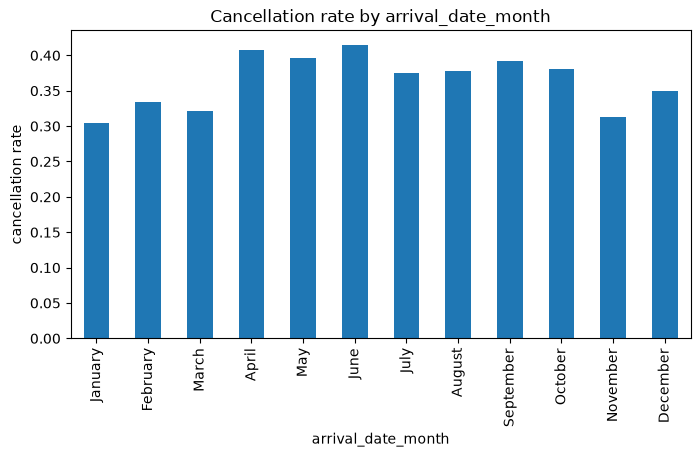

                  rate      n
hotel                        
City Hotel    0.417270  79330
Resort Hotel  0.277634  40060


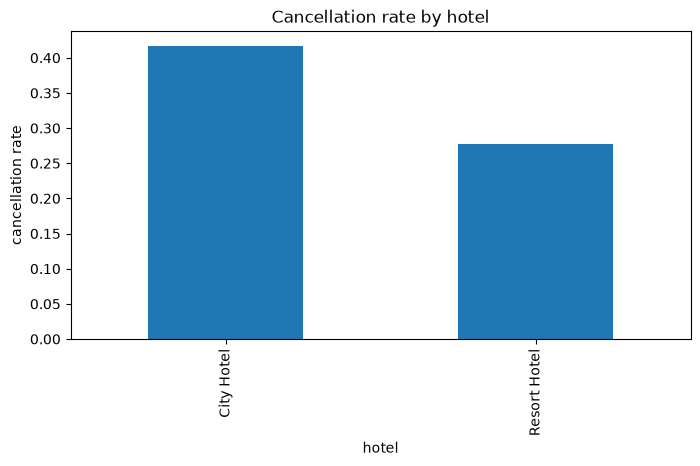

                  rate       n
deposit_type                  
No Deposit    0.283770  104641
Non Refund    0.993624   14587
Refundable    0.222222     162


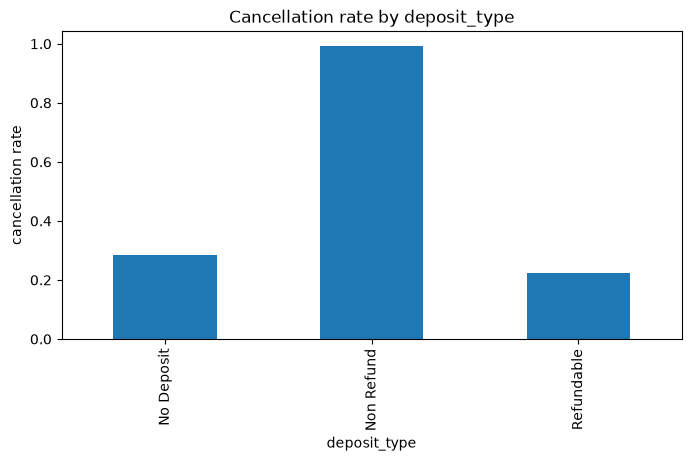

                    rate      n
market_segment                 
Aviation        0.219409    237
Complementary   0.130552    743
Corporate       0.187347   5295
Direct          0.153419  12606
Groups          0.610620  19811
Offline TA/TO   0.343160  24219
Online TA       0.367211  56477
Undefined       1.000000      2


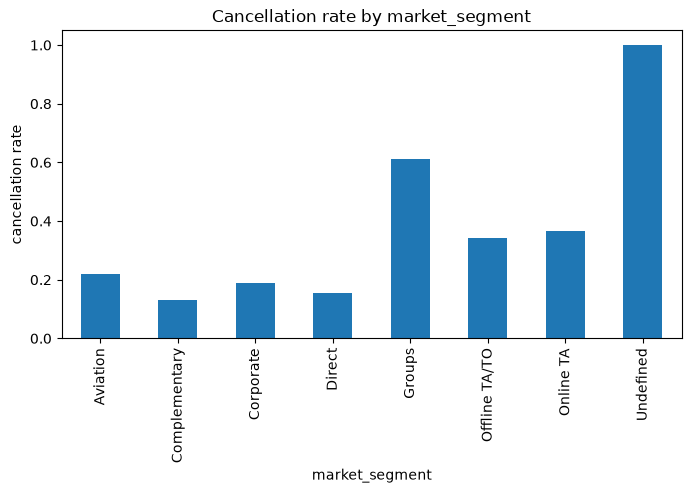

In [58]:
cancel_rate(df, "arrival_date_month", order=month_order)
cancel_rate(df, "hotel")
cancel_rate(df, "deposit_type")
cancel_rate(df, "market_segment")


                 rate      n
lead_bucket                 
0-7          0.096323  19746
8-30         0.278639  18960
31-90        0.376984  29553
91-180       0.447105  26439
181-365      0.554540  21544
365+         0.676620   3148


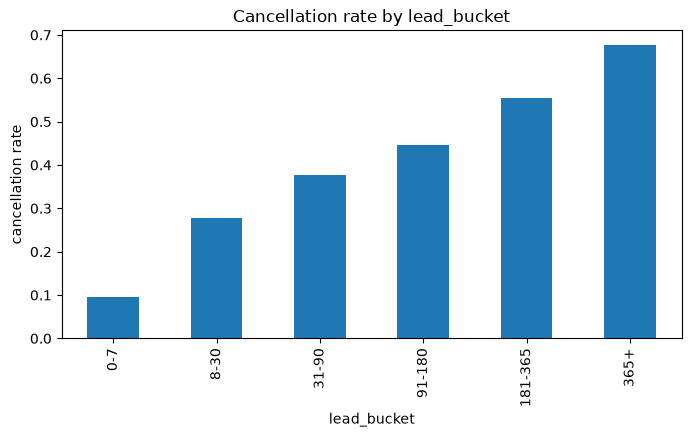

In [59]:
df["lead_bucket"] = pd.cut(df["lead_time"],
                           bins=[-1, 7, 30, 90, 180, 365, np.inf],
                           labels=["0-7","8-30","31-90","91-180","181-365","365+"])

cancel_rate(df, "lead_bucket")

In [60]:
df[df["deposit_type"]=="No Deposit"].groupby("lead_bucket")["is_canceled"].mean()

lead_bucket
0-7        0.091646
8-30       0.260440
31-90      0.321898
91-180     0.348607
181-365    0.398240
365+       0.206250
Name: is_canceled, dtype: float64

<Axes: xlabel='adr', ylabel='Count'>

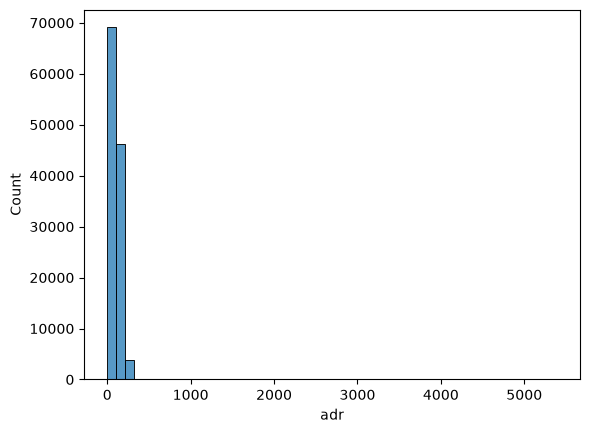

In [61]:
sns.histplot(df["adr"], bins=50)

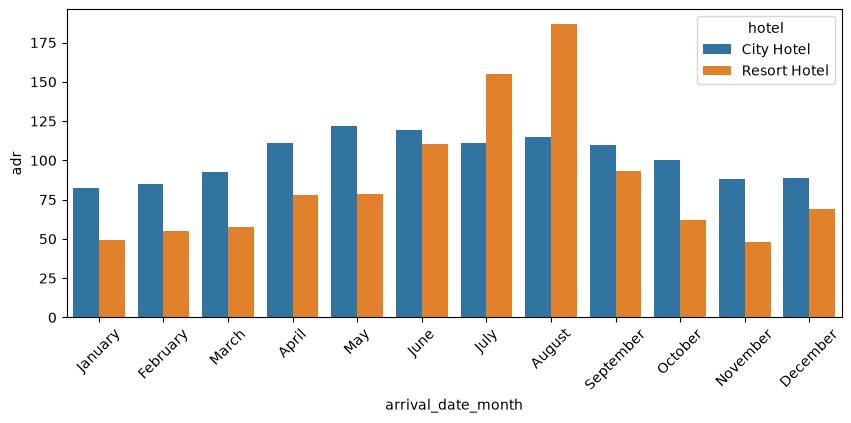

In [62]:
adr_by_month = (df.groupby(["arrival_date_month", "hotel"])["adr"]
                  .mean()
                  .reset_index())          # turns the index back into columns

plt.figure(figsize=(10,4))
sns.barplot(data=adr_by_month, x="arrival_date_month", y="adr",
            hue="hotel", order=month_order)
plt.xticks(rotation=45)
plt.show()

is_canceled                       1.000000
lead_time                         0.293123
total_of_special_requests         0.234658
required_car_parking_spaces       0.195498
booking_changes                   0.144381
previous_cancellations            0.110133
is_repeated_guest                 0.084793
agent                             0.083114
adults                            0.060017
previous_bookings_not_canceled    0.057358
days_in_waiting_list              0.054186
adr                               0.047557
babies                            0.032491
stays_in_week_nights              0.024765
company                           0.020642
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
arrival_date_day_of_month         0.006130
children                          0.005048
stays_in_weekend_nights           0.001791
Name: is_canceled, dtype: float64

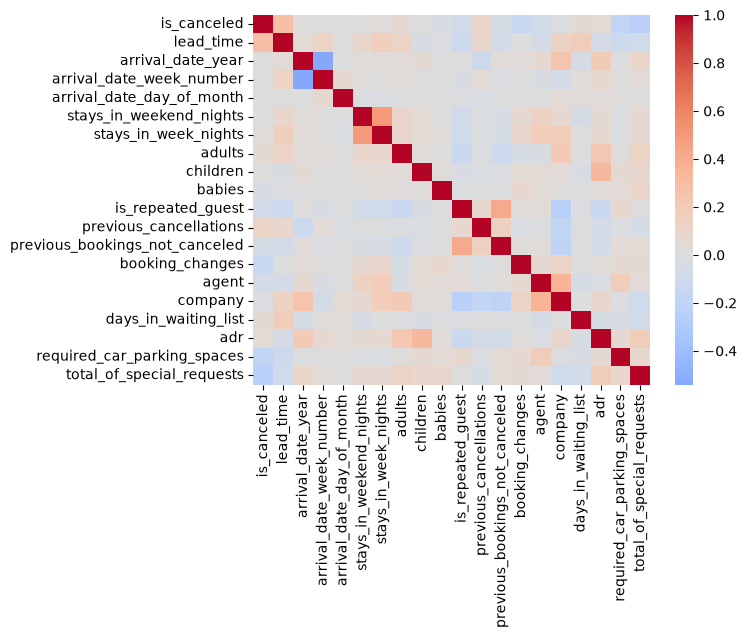

In [63]:
corr = df.select_dtypes("number").corr()

sns.heatmap(corr, cmap="coolwarm", center=0)
corr["is_canceled"].abs().sort_values(ascending=False)

In [64]:
df["is_canceled"].value_counts(normalize=True)

is_canceled
0    0.629584
1    0.370416
Name: proportion, dtype: float64

### **Step 3: Cleaning**


In [65]:
row = df.copy()

log = []

def note(step):
    log.append((step, len(df)))
    print(f"{step}: {len(df):,} rows \n")

    print("Logs : ")
    for i in log :
        print(i)

note("start")

start: 119,390 rows 

Logs : 
('start', 119390)


#### 1. Drop the leakage columns
* The reservation_status and the reservation_date_change is not exist at the prediction time and it will reveal the outcome. So we will drop them 

In [66]:
df = df.drop(columns=["reservation_status", "reservation_status_date"])


#### 2. Missing values handling

In [67]:
df.isna().sum()[lambda s: s > 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

In [68]:
# Droping the company column because about 94% of the rows are missign, so there is nothing to learn from that column
df = df.drop(columns=["company"])

In [69]:
# Missing values in the childern column are fill with 0 because it has few missing values and fill that with the 0 is the sensible default 
df["children"] = df["children"].fillna(0)

In [70]:
# replace the missing country rows with the Unknown because missing country is itself a category 
df["country"] = df["country"].fillna("Unknown")

In [71]:
#replace the missing agent values with unknown because missing agent means no agent envolve here ( a direcct booking )
df["agent"] = df["agent"].apply(lambda x: "Unknown" if pd.isna(x) else str(int(x)))
# .apply() = runs the function on every value of , one at a time
# lambda x = A short , nameless function where x is the current value
# "Unknown" if pd.isna(x) else str(int(x)) = if the value is missing replace it with the unknown, otherwise covert it to a whole number(int) then to a string 
# we convert the column into a string because the agent values have no order and by converting it to a string makes the pipeline treat them as a categories  


#### 3. Remove impossible rows

In [72]:
# Checking the values 
bad_adr_neg = df["adr"] < 0
no_guests = (df["adults"] + df["children"] + df["babies"] ) == 0
no_nights = (df["stays_in_week_nights"] + df["stays_in_weekend_nights"]) == 0 

print(bad_adr_neg.sum(), no_guests.sum(), no_nights.sum())

1 180 715


In [73]:
# checking the adr column 
print(df["adr"].quantile([0.99, 0.999, 0.9999]))
print(df["adr"].sort_values(ascending=False).head(10))

0.9900    252.00000
0.9990    326.20163
0.9999    388.00000
Name: adr, dtype: float64
48515     5400.00
111403     510.00
15083      508.00
103912     451.50
13142      450.00
13391      437.00
39155      426.25
39568      402.00
39118      397.38
13323      392.00
Name: adr, dtype: float64


In [74]:
ADR_MAX = 1000
too_high_adr = df["adr"] > ADR_MAX
# this will remove the impossible value (5400) from the dataset 
# The next highest value is 510 , and values are gradually from there, so 5400 is the only break in the pattern. I used a cut off of 1000, which lies inside that gap.

#Remove the invalid rows from the dataset
df = df[~(bad_adr_neg | too_high_adr | no_nights | no_guests)]
note("After removing invalid rows")

After removing invalid rows: 118,563 rows 

Logs : 
('start', 119390)
('After removing invalid rows', 118563)


#### 4. Duplicates

In [75]:
df.duplicated().sum()

np.int64(32192)

In [76]:
df = df.drop_duplicates()
note("after dropping duplicates")

# I dropped them because duplicates across train and test would inflate scores, though without a booking ID a few could be genuine repeats.

after dropping duplicates: 86,371 rows 

Logs : 
('start', 119390)
('After removing invalid rows', 118563)
('after dropping duplicates', 86371)


#### 5. Final checks and save

In [77]:
df = df.reset_index(drop=True)
print(df.shape)
print("missing values left:", df.isna().sum().sum())     # should be 0
print(df["adr"].describe())                               # min >= 0, sensible max
print(df["is_canceled"].value_counts(normalize=True))     # roughly 63/37 still?
df.to_csv("../data/clean/hotel_clean.csv", index=False)

(86371, 30)
missing values left: 0
count    86371.000000
mean       107.214452
std         51.325798
min          0.000000
25%         72.900000
50%         99.000000
75%        134.505000
max        510.000000
Name: adr, dtype: float64
is_canceled
0    0.725301
1    0.274699
Name: proportion, dtype: float64


### **Step 4: Feature engineering**



| Feature | How it's built | Why (business reasoning) |
|---|---|---|
| **`total_nights`** | weekend nights + week nights | Length of stay is a single, meaningful booking size. Two separate night columns describe it indirectly. It should help price (longer stays may get discounted rates) and cancellation (longer stays are bigger commitments). |
| **`total_guests`** | adults + children + babies | Party size drives room type and price, and it is the base for the family and group patterns. A single count is easier for models than three separate columns. |
| **`is_family`** | 1 if children or babies are present | Families plan differently from solo or business travellers: they book around school holidays, want larger rooms, and may cancel differently. The flag captures this in one signal, where `children` and `babies` alone split it across two sparse columns. |
| **`weekend_ratio`** | weekend nights / total nights | Separates leisure trips (weekend-heavy) from business trips (weekday-heavy). `total_nights` alone can't do this, since a 2-night Saturday stay and a 2-night Tuesday stay look the same. It's a possible price driver, since weekend rates often differ. |
| **`season`** | month mapped to winter, spring, summer or autumn | Months with similar demand behave alike, so grouping them reduces 12 categories to 4 and makes the seasonal pattern clearer. |


In [78]:
df["total_nights"] = df["stays_in_week_nights"] + df["stays_in_weekend_nights"]
df["total_guests"] =df["adults"] + df["babies"] + df["children"]
df["is_family"] = ( (df["children"] > 0 ) | (df["babies"] > 0)).astype(int)
df["weekend_ratio"] = (df["stays_in_weekend_nights"] / df["total_nights"])

season_map = {
    "December": "winter", "January": "winter", "February": "winter",
    "March": "spring", "April": "spring", "May": "spring",
    "June": "summer", "July": "summer", "August": "summer",
    "September": "autumn", "October": "autumn", "November": "autumn"
}

df["season"] = df["arrival_date_month"].map(season_map)

In [79]:
# check if any missing values are created in the new columns 
print(df[["total_nights","total_guests","weekend_ratio","season"]].isna().sum())
print(df["season"].value_counts())
print(df["weekend_ratio"].between(0, 1).all())   # should be True


total_nights     0
total_guests     0
weekend_ratio    0
season           0
dtype: int64
season
summer    28841
spring    23520
autumn    18342
winter    15668
Name: count, dtype: int64
True


### **Step 4: Split and build the pipeline**

In [80]:
# Choose one split for all modules
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["is_canceled"], random_state=42
)

print(train_df["is_canceled"].mean(), test_df["is_canceled"].mean())   

0.274704758596735 0.27467438494934876


In [81]:
# Separate features from targets

TARGETS = ["is_canceled", "adr"]
X_train = train_df.drop(columns=TARGETS)
X_test  = test_df.drop(columns=TARGETS)

y_cancel_train, y_cancel_test = train_df["is_canceled"], test_df["is_canceled"]
y_adr_train,    y_adr_test    = train_df["adr"],         test_df["adr"]

In [82]:
# drop lead_bucket that created for the EDA plot. It is just a re-labelled lead_time,
X_train = X_train.drop(columns=["lead_bucket"], errors="ignore")
X_test  = X_test.drop(columns=["lead_bucket"], errors="ignore")

In [83]:
# Sort columns into numeric and categorical
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
print(num_cols); print(cat_cols)

['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights', 'total_guests', 'is_family', 'weekend_ratio']
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'agent', 'customer_type', 'season']


/var/folders/pq/0_j6ygpn76vgqyzsc33qgbcw0000gn/T/ipykernel_86277/2784919747.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include="object").columns.tolist()


In [84]:
# Build the preprocessor

# Numerical preprocessing pipeline 
num_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
])

# Categorical Preprocessing pipeline 
cat_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="most_frequent")),
    ("oh", OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency= 100,
        sparse_output=False
    )),
]) 


preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

In [ ]:
# Fit on train and transform both 

X_train_p = preprocess.fit_transform(X_train)
X_test_p = preprocess.transform(X_test)

print(X_train_p.shape, X_test_p.shape)    # same number of columns
print(X_train_p[:, :len(num_cols)].mean(axis=0).round(2))   # ≈ 0
print(X_test_p[:, :len(num_cols)].mean(axis=0).round(2))    # close to 0, but not exactly

# Train means are about 0, and test means are close but not exactly 0. So that proves the scaler used the training statistics 


(69096, 172) (17275, 172)
[ 0.  0.  0.  0. -0.  0. -0. -0. -0.  0.  0.  0.  0.  0. -0. -0. -0.  0.
 -0.  0.]
[-0.01 -0.    0.    0.    0.    0.    0.   -0.01  0.01 -0.01 -0.   -0.
  0.    0.01 -0.01 -0.01  0.   -0.   -0.01  0.  ]
